# Readmission Prediction — Improved Pipeline (v3)

โน้ตบุ๊กนี้รวบข้อมูล + feature engineering + การจัดการ imbalance + โมเดล + metric ที่เหมาะกับปัญหานี้ไว้ในที่เดียว ต่อยอดจากไฟล์ `02_preprocessing` / `03_model_preparation` / `04_model_training` เดิม โดยเพิ่ม:

1. ฟีเจอร์ proxy สำหรับพฤติกรรมดูแลตัวเอง/engagement ของผู้ป่วย (การปรับยา, การตรวจติดตาม, จำนวนโรคร่วม)
2. เปรียบเทียบเทคนิคจัดการ imbalance หลายแบบก่อนเลือกใช้ (ไม่เดาว่า SMOTE ดีที่สุด)
3. Metric ที่ออกแบบมาสำหรับปัญหานี้โดยเฉพาะ: PR-AUC เป็นหลัก, Precision@k (จำลองว่าโรงพยาบาลติดตามผู้ป่วยได้จำกัด), F2 (เน้น recall เพราะพลาดเคส readmit costly กว่า false alarm), และ cost-based threshold

⚠️ **หมายเหตุสำคัญ (จากผลการทดลองก่อนหน้า)**: ฟีเจอร์ proxy ที่เพิ่มใหม่ (จำนวนการปรับยา, การตรวจ A1C/glucose, จำนวนโรคร่วม) มี correlation กับ target ต่ำมาก (~0.01-0.04) เมื่อเทียบกับ `total_prior_visits`/`had_prior_inpatient` เดิม (~0.12-0.13) — ใส่ไว้เพราะไม่เสียหายและช่วยให้ SHAP อธิบายได้ครบขึ้น แต่ไม่ควรคาดหวังว่าจะพลิกผล F1 อย่างมีนัยสำคัญ เพดานของปัญหายังคงเป็นข้อจำกัดของข้อมูลระดับ encounter ไม่ใช่การขาดฟีเจอร์เหล่านี้

## 1. Import

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report, brier_score_loss,
)
from xgboost import XGBClassifier

# pip install imbalanced-learn shap ถ้ายังไม่มี
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
import shap

RANDOM_STATE = 42

## 2. Load & Clean Data

เหมือน `02_preprocessing.ipynb` เดิม (ตัดแถวที่เสียชีวิต/hospice, gender ที่ผิดปกติ) แต่รวบไว้ในที่เดียวเพื่อความสะดวก

In [2]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df.shape}")

# ตัด gender ที่ผิดปกติ
df = df[df["gender"] != "Unknown/Invalid"]

# ตัดผู้ป่วยที่ discharge เป็น เสียชีวิต/hospice เพราะไม่มีทาง readmit ได้จริง
death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]
# สำคัญ: เรียงข้อมูลตาม patient_nbr แล้วตาม encounter_id ก่อน reset_index
# dataset นี้ไม่มีคอลัมน์วันที่/เวลาเลย แต่ encounter_id เพิ่มขึ้นแบบ monotonic
# ตามลำดับเวลาจริงสำหรับผู้ป่วยแต่ละคน (ตรวจสอบกับข้อมูลจริงแล้ว) จึงใช้แทน
# ลำดับเวลาโดยประมาณได้ เพื่อสร้างฟีเจอร์ประวัติข้าม encounter ในหัวข้อ 3 ต่อไป
df = df.sort_values(["patient_nbr", "encounter_id"])
df = df.reset_index(drop=True)  # สำคัญ: รีเซ็ต index ให้เรียง 0..n-1 ใหม่
# เพราะการตัดแถวด้านบนทำให้ index เดิมมีช่องว่าง ถ้าไม่ reset ตอน GroupShuffleSplit
# คืนตำแหน่ง (positional) 0..n-1 มาจะไม่ตรงกับ label เดิมของ df -> .loc[] จะหาไม่เจอ (KeyError)
print(f"Shape after cleaning: {df.shape}")

Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)


## 3. Feature Engineering

### 3.1 ฟีเจอร์ engagement/self-care แบบ proxy (ใหม่)

dataset นี้ไม่มีข้อมูลพฤติกรรมผู้ป่วยตรงๆ แต่มีคอลัมน์ที่พอใช้เป็น proxy ได้:
- **medication_change_count**: จำนวนยาที่แพทย์ต้องปรับ (Up/Down) — สะท้อนว่าควบคุมโรคด้วยยาเดิมไม่ได้
- **num_meds_active**: จำนวนยาที่ผู้ป่วยใช้อยู่ ณ ตอนนั้น — ความซับซ้อนของการรักษา
- **tested_glucose / tested_A1C**: มีการตรวจติดตามหรือไม่ — พอเป็นสัญญาณของการดูแลติดตามอาการ
- **comorbidity_count**: จำนวนกลุ่มโรคที่ต่างกันใน diag_1-3 — ความซับซ้อนของเคส

In [3]:
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]

df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

### 3.1B ประวัติข้าม encounter ของผู้ป่วยคนเดียวกัน (longitudinal features — ใหม่)

⚠️ **แก้ไขจากไอเดียเดิม**: `diabetic_data.csv` ไม่มีคอลัมน์วันที่/เวลาเลยสักตัว จึงคำนวณ "ระยะห่างระหว่างการมาแต่ละครั้งเป็นวัน" ไม่ได้ตรงๆ แต่ `encounter_id` เพิ่มขึ้นแบบ monotonic ตามลำดับเวลาจริงสำหรับผู้ป่วยแต่ละคน (ตรวจสอบกับข้อมูลจริงแล้วในตัวอย่างผู้ป่วยที่มาซ้ำหลายครั้ง) จึงใช้เป็นลำดับเวลาโดยประมาณแทนได้ (ข้อมูลถูกเรียงตาม `patient_nbr`, `encounter_id` ไว้แล้วในหัวข้อ 2)

- **visit_number**: ครั้งที่เท่าไหร่ของผู้ป่วยคนนี้ในข้อมูลทั้งหมด (ทดสอบแล้ว correlation กับ target = 0.140 — สูงกว่าฟีเจอร์อื่นทั้งหมดที่เคยลองมา)
- **prior_change_count**: จำนวนครั้งที่เคยถูกปรับยาใน encounter **ก่อนหน้า** ของผู้ป่วยคนเดียวกัน (ใช้ `.cumsum() - ตัวเอง` เพื่อไม่ให้ข้อมูลของ encounter ปัจจุบันรั่วเข้าไปในฟีเจอร์ของตัวเอง — ป้องกัน data leakage) — correlation = 0.113

In [4]:
df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1

df["change_flag"] = (df["change"] == "Ch").astype(int)
# cumsum() รวมค่าของแถวปัจจุบันด้วย จึงต้องลบตัวเองออกเพื่อให้เหลือแค่ "ก่อนหน้า" เท่านั้น
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])  # ใช้แค่คำนวณ cumsum ชั่วคราว ไม่ใช่ฟีเจอร์จริง

### 3.2 ฟีเจอร์จำนวนครั้งที่มาโรงพยาบาลก่อนหน้า (เดิม — คงไว้เพราะเป็นตัวทำนายที่แข็งแรงที่สุด)

In [5]:
df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)

### 3.2B ภาวะแทรกซ้อนของเบาหวาน (diabetes-with-complications flag — ใหม่)

ต้องทำ**ก่อน**หัวข้อ 3.3 ที่จะเขียนทับ `diag_1-3` ด้วยชื่อกลุ่มโรค เพราะต้องใช้รหัส ICD-9 ดิบ

หลักการ: ICD-9 `250.0-250.3` = เบาหวานที่ยังไม่มีภาวะแทรกซ้อน, `250.4-250.9` = เบาหวานที่มีภาวะแทรกซ้อนแล้ว (nephropathy/retinopathy/neuropathy ฯลฯ) ซึ่งเป็นผลจากการคุมน้ำตาลไม่ดีต่อเนื่องมานาน — ทดสอบกับข้อมูลจริงแล้ว readmit rate กระโดดจาก 10.7% (ไม่มี flag) เป็น 15.4% (มี flag) correlation กับ target = 0.044

In [6]:
def is_diabetes_complicated(code):
    if pd.isna(code):
        return False
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return False
    try:
        val = float(code)
    except ValueError:
        return False
    return 250.4 <= val <= 250.99

df["diabetes_complicated"] = df[["diag_1", "diag_2", "diag_3"]].apply(
    lambda row: int(any(is_diabetes_complicated(v) for v in row)), axis=1
)

### 3.3 จัดกลุ่มการวินิจฉัย (diag_1-3) และนับจำนวนกลุ่มโรคร่วม (comorbidity_count)

In [7]:
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})

# นับจำนวนกลุ่มโรคที่ไม่ซ้ำกัน (ไม่นับ Missing) จาก diag_1-3 -> ยิ่งเยอะยิ่งซับซ้อน
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)

for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

### 3.4 Interaction features

ฟีเจอร์เชิงผสมที่อาจจับ pattern ที่ฟีเจอร์เดี่ยวจับไม่ได้ — โมเดล tree-based (RF/XGBoost) จับ interaction เองได้ในระดับหนึ่งอยู่แล้ว แต่การใส่ตรงๆ ช่วยให้ meta-learner (Logistic Regression) ที่เป็น linear model เห็น pattern นี้ได้ด้วย

In [8]:
df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})

df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

### 3.5 ลด/ตัดคอลัมน์ + จัดกลุ่ม medical_specialty (เหมือนเดิม)

In [9]:
drop_cols = ["weight", "payer_code", "encounter_id"]
df.drop(columns=drop_cols, inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(
    df["medical_specialty"].isin(top_specialties), "Other"
)

df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Dropping constant columns: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)

Dropping constant columns: ['examide', 'citoglipton']


### 3.6 Target Variable

In [10]:
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)
print(df["readmitted"].value_counts(normalize=True))

readmitted
0    0.886108
1    0.113892
Name: proportion, dtype: float64


### 3.7 ตรวจสอบสัญญาณของฟีเจอร์ใหม่ก่อนใช้งานจริง

เช็ค correlation กับ target ก่อน — ถ้าฟีเจอร์ proxy ใหม่แทบไม่มี correlation เลย ให้ตั้งความคาดหวังไว้ล่วงหน้าว่าอาจไม่ได้ช่วยมาก (SHAP ในขั้นตอนหลังจะช่วยยืนยันอีกที)

In [11]:
check_cols = [
    "medication_change_count", "num_meds_active", "tested_glucose", "tested_A1C",
    "comorbidity_count", "total_prior_visits", "had_prior_inpatient",
    "age_x_medications", "hospital_stay_x_inpatient",
    "visit_number", "prior_change_count", "diabetes_complicated",  # ฟีเจอร์ใหม่ (longitudinal + complication flag)
]
print(df[check_cols + ["readmitted"]].corr()["readmitted"].sort_values(key=abs, ascending=False))

readmitted                   1.000000
visit_number                 0.140079
hospital_stay_x_inpatient    0.135865
total_prior_visits           0.127930
had_prior_inpatient          0.124666
prior_change_count           0.112658
age_x_medications            0.044329
diabetes_complicated         0.043663
medication_change_count      0.035634
tested_A1C                  -0.020631
tested_glucose               0.010036
comorbidity_count            0.009162
num_meds_active              0.000932
Name: readmitted, dtype: float64


## 4. Encode + Train/Test Split (GroupShuffleSplit ตาม patient_nbr)

In [12]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

feature_cols = [c for c in X.columns if c != GROUP_COL]
# ใช้ pd.api.types.is_string_dtype() แทน select_dtypes(include=["object","str"])
# เพราะ "str" เป็น dtype token ที่ pandas บางเวอร์ชันตีความเป็น numpy string dtype (<U)
# แล้วโดน pandas ปฏิเสธด้วย TypeError ("numpy string dtypes are not allowed")
# is_string_dtype() ครอบคลุมทั้ง object dtype แบบเก่า และ string dtype แบบใหม่ ปลอดภัยกว่า
categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
if "age" in categorical_cols:
    categorical_cols.remove("age")  # แทนที่ด้วย age_ord ที่เป็นตัวเลขแล้ว
X = X.drop(columns=["age"])
numeric_cols = [c for c in feature_cols if c not in categorical_cols and c != "age"]

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

X_train.drop(columns=[GROUP_COL], inplace=True)
X_test.drop(columns=[GROUP_COL], inplace=True)

# ใช้ .iloc ไม่ใช่ .loc เพราะ train_idx/test_idx จาก GroupShuffleSplit เป็นตำแหน่ง (positional)
overlap = set(df.iloc[train_idx][GROUP_COL]) & set(df.iloc[test_idx][GROUP_COL])
print(f"Patient overlap (ต้องเป็น 0): {len(overlap)}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target rate: {y_train.mean():.4f}, Test target rate: {y_test.mean():.4f}")

Patient overlap (ต้องเป็น 0): 0
Train: (79567, 55), Test: (19773, 55)
Train target rate: 0.1140, Test target rate: 0.1135


## 5. เปรียบเทียบเทคนิคจัดการ Imbalance ก่อนเลือกใช้

แทนที่จะเลือก SMOTE ไปเลย ให้เทียบ SMOTE / BorderlineSMOTE / ADASYN / class_weight="balanced" (ไม่ resample) บน base model เดียวกัน (RandomForest ค่า default) ด้วย 3-fold CV โดยวัดด้วย **average_precision (PR-AUC)** ซึ่งเหมาะกับข้อมูล imbalance มากกว่า accuracy/ROC-AUC เพราะไม่ถูก dominate โดย class ส่วนใหญ่

In [13]:
from sklearn.model_selection import cross_val_score

# หมายเหตุ: RandomForestClassifier ทุกตัวด้านล่างตั้งใจใช้ n_jobs=1 (ไม่ใช่ -1)
# เพราะ cross_val_score ด้านล่างใช้ n_jobs=-1 อยู่แล้ว ถ้าให้ทั้งสองชั้น parallelize
# พร้อมกัน (nested parallelism) จะทำให้ Windows ขึ้น OSError/WinError 1450
# (resource ไม่พอ) เพราะพยายามสร้าง process จำนวนมากเกินไปพร้อมกัน
resampling_options = {
    "SMOTE": ImbPipeline([
        ("resample", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "BorderlineSMOTE": ImbPipeline([
        ("resample", BorderlineSMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "ADASYN": ImbPipeline([
        ("resample", ADASYN(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "class_weight_balanced (no resample)": RandomForestClassifier(
        n_estimators=200, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
    ),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
results = {}
for name, pipe in resampling_options.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    results[name] = scores.mean()
    print(f"{name:38s} PR-AUC (CV mean): {scores.mean():.4f} (+/- {scores.std():.4f})")

best_resampler_name = max(results, key=results.get)
print(f"\n>>> เลือกใช้: {best_resampler_name}")

SMOTE                                  PR-AUC (CV mean): 0.1492 (+/- 0.0011)
BorderlineSMOTE                        PR-AUC (CV mean): 0.1574 (+/- 0.0009)
ADASYN                                 PR-AUC (CV mean): 0.1447 (+/- 0.0008)
class_weight_balanced (no resample)    PR-AUC (CV mean): 0.2069 (+/- 0.0068)

>>> เลือกใช้: class_weight_balanced (no resample)


## 5B. (ทดลอง) Synthetic Minority Oversampling ด้วย Generative Model (SDV)

ลองเทคนิคที่ต่างจาก SMOTE family โดยพื้นฐาน — ใช้ **Gaussian Copula** (จาก library `sdv`) เรียนรู้การกระจายตัวร่วม (joint distribution) ของฟีเจอร์ทั้งหมดใน minority class แล้วสุ่มตัวอย่างใหม่จากการกระจายตัวนั้น แทนการ interpolate เชิงเส้นแบบ SMOTE

```bash
pip install sdv --break-system-packages
```

⚠️ **ตั้งความคาดหวังไว้ก่อน**: จากผลในขั้นตอนที่ 5 ที่ SMOTE/BorderlineSMOTE/ADASYN ทุกตัวแพ้ `class_weight="balanced"` ธรรมดา มีโอกาสสูงที่ CTGAN/Gaussian Copula จะแพ้เหมือนกัน — นี่คือการทดลองเพิ่มเติมเพื่อให้ครบถ้วน ไม่ใช่คำตอบที่รับประกันว่าจะดีขึ้น ถ้าผลออกมาแพ้ class_weight อีก ให้ใช้เป็นหลักฐานสนับสนุนว่าปัญหาไม่ได้อยู่ที่ 'วิธี resample' แต่อยู่ที่สัญญาณในข้อมูลจริงๆ

In [14]:
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import SingleTableMetadata

class SyntheticMinorityOversampler:
    """Resampler ที่ implement fit_resample(X, y) เข้ากับ imblearn.pipeline.Pipeline ได้เหมือน SMOTE
    (imblearn เช็คแค่ hasattr(obj, 'fit_resample') ไม่ได้บังคับ inherit จาก base class ใดๆ)

    ใช้ Gaussian Copula เรียนรู้การกระจายตัวร่วมของฟีเจอร์ใน minority class แล้วสุ่มตัวอย่างสังเคราะห์ใหม่
    แทนการ interpolate เชิงเส้นระหว่างจุดข้อมูลที่ใกล้กันแบบ SMOTE"""

    def __init__(self, target_ratio=1.0, random_state=42):
        self.target_ratio = target_ratio
        self.random_state = random_state

    def fit_resample(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(y).reset_index(drop=True)

        minority_class = y.value_counts().idxmin()
        minority_df = X[y == minority_class].copy()

        n_majority = int((y != minority_class).sum())
        n_minority = int((y == minority_class).sum())
        n_needed = int(n_majority * self.target_ratio) - n_minority
        if n_needed <= 0:
            return X, y

        # ระบุ metadata เอง (auto-detect ของ sdv อาจตีความคอลัมน์ categorical ที่ label-encode
        # เป็นตัวเลขแล้ว (เช่น gender, race) เป็น numerical ผิดประเภทได้ -- ควรตรวจสอบ/แก้ไข
        # metadata ให้ตรงก่อนใช้งานจริง โค้ดนี้ใช้ auto-detect เป็นจุดเริ่มต้นเท่านั้น)
        metadata = SingleTableMetadata()
        metadata.detect_from_dataframe(minority_df)

        synthesizer = GaussianCopulaSynthesizer(metadata)
        synthesizer.fit(minority_df)
        synthetic_rows = synthesizer.sample(num_rows=n_needed)

        X_res = pd.concat([X, synthetic_rows[X.columns]], ignore_index=True)
        y_res = pd.concat(
            [y, pd.Series([minority_class] * n_needed)], ignore_index=True
        )
        return X_res, y_res

In [15]:
# เทียบกับผลลัพธ์เดิมจากขั้นตอนที่ 5 (SMOTE / BorderlineSMOTE / ADASYN / class_weight)
synthetic_pipeline = ImbPipeline([
    ("resample", SyntheticMinorityOversampler(target_ratio=1.0, random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)),
])

# หมายเหตุ: การ fit GaussianCopulaSynthesizer ทุก fold ระหว่าง cross_val_score จะช้ากว่า SMOTE มาก
# (เป็นสาเหตุที่ต้องใช้ cv น้อย fold กว่าปกติในเซลล์นี้ ถ้าเครื่องแรงพอ ปรับ cv ให้เท่ากับขั้นตอนที่ 5 ได้)
cv_small = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
synthetic_scores = cross_val_score(
    synthetic_pipeline, X_train, y_train, cv=cv_small, scoring="average_precision", n_jobs=1,
)
print(f"Gaussian Copula Synthetic Oversampling   PR-AUC (CV mean): {synthetic_scores.mean():.4f} (+/- {synthetic_scores.std():.4f})")

# สำคัญ: เพิ่มผลลัพธ์นี้เข้าไปใน `results` dict เดียวกับขั้นตอนที่ 5 แล้วเลือก best_resampler_name ใหม่
# ทำให้ Gaussian Copula "แข่ง" กับ SMOTE/BorderlineSMOTE/ADASYN/class_weight อย่างเป็นธรรม
# และถ้าชนะจริง จะถูกใช้ต่อในหัวข้อ 6-12 โดยอัตโนมัติ (ไม่ใช่แค่พิมพ์ตัวเลขเทียบเฉยๆ เหมือนเดิม)
results["GaussianCopula (SDV)"] = synthetic_scores.mean()
best_resampler_name = max(results, key=results.get)

print("\nสรุปผลทุกวิธี (PR-AUC เฉลี่ยจาก CV):")
for name, score in sorted(results.items(), key=lambda kv: -kv[1]):
    marker = "  <-- เลือกใช้" if name == best_resampler_name else ""
    print(f"  {name:38s} {score:.4f}{marker}")

Gaussian Copula Synthetic Oversampling   PR-AUC (CV mean): 0.1935 (+/- 0.0006)

สรุปผลทุกวิธี (PR-AUC เฉลี่ยจาก CV):
  class_weight_balanced (no resample)    0.2069  <-- เลือกใช้
  GaussianCopula (SDV)                   0.1935
  BorderlineSMOTE                        0.1574
  SMOTE                                  0.1492
  ADASYN                                 0.1447


## 6. Define Base Models (ใช้เทคนิค imbalance ที่เลือกจากขั้นตอนที่ 5 + 5B)

⚠️ ยังคง**ห่อ resampler เข้ากับแต่ละโมเดลผ่าน `ImbPipeline`** ห้าม resample `X_train` ตรงๆ ครั้งเดียว เพราะจะทำให้ตัวอย่างสังเคราะห์หลุดเข้าไปใน validation fold ระหว่าง cross-validation (data leakage) — ใน `RandomizedSearchCV` และ `StackingClassifier` (cv=5) โมเดลจะ resample ใหม่ทุก fold โดยอัตโนมัติ

🐢 **ถ้า `best_resampler_name` กลายเป็น "GaussianCopula (SDV)"**: ขั้นตอนที่ 7 (`RandomizedSearchCV`, cv=3, n_iter=10) และขั้นตอนที่ 8 (`StackingClassifier`, cv=5) จะเรียก fit Gaussian Copula synthesizer **ใหม่ทุกครั้ง** ที่มีการ fit บนแต่ละ fold — รวมแล้วอาจถึงหลักสิบครั้ง ซึ่งช้ากว่า SMOTE/class_weight มาก (นาทีถึงหลักสิบนาที ขึ้นกับเครื่อง) เตรียมใจรอให้นานขึ้น หรือถ้าอยากลดเวลา ให้ลด `n_iter`/`cv` ในขั้นตอนที่ 7 ลงชั่วคราว

In [16]:
print(f"ใช้เทคนิคจัดการ imbalance: {best_resampler_name}")  # ยืนยันว่าหัวข้อนี้ใช้ผลจากขั้นตอนที่ 5+5B จริง ไม่ใช่ hardcode

# เพิ่ม "GaussianCopula (SDV)" เข้ามาด้วย เพื่อให้ make_pipeline() รู้จักและใช้ต่อได้
# ถ้า best_resampler_name (จากขั้นตอนที่ 5+5B) กลายเป็นตัวนี้
resampler_map = {
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "BorderlineSMOTE": BorderlineSMOTE(random_state=RANDOM_STATE),
    "ADASYN": ADASYN(random_state=RANDOM_STATE),
    "GaussianCopula (SDV)": SyntheticMinorityOversampler(target_ratio=1.0, random_state=RANDOM_STATE),
}

def make_pipeline(estimator_name, estimator):
    if best_resampler_name in resampler_map:
        return ImbPipeline([
            ("resample", resampler_map[best_resampler_name]),
            (estimator_name, estimator),
        ])
    return Pipeline([(estimator_name, estimator)])  # class_weight ฝังอยู่ใน estimator เอง

rf_pipeline = make_pipeline("rf", RandomForestClassifier(
    n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=1,  # n_jobs=1 ตั้งใจ: กัน nested parallelism กับ RandomizedSearchCV(n_jobs=-1) ในหัวข้อ 7
    class_weight=None if best_resampler_name in resampler_map else "balanced",
))

xgb_pipeline = make_pipeline("xgboost", XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,  # เหตุผลเดียวกัน: กัน nested parallelism
    scale_pos_weight=1 if best_resampler_name in resampler_map else (y_train == 0).sum() / (y_train == 1).sum(),
))

ใช้เทคนิคจัดการ imbalance: class_weight_balanced (no resample)


## 7. Hyperparameter Tuning (scoring = average_precision)

In [17]:
rf_param_dist = {
    "rf__n_estimators": [200, 300, 500],
    "rf__max_depth": [8, 12, 16],
    "rf__min_samples_leaf": [1, 2, 5],
}
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_param_dist, n_iter=10, cv=3,
    scoring="average_precision", n_jobs=-1, random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best RF PR-AUC (CV):", rf_search.best_score_)
rf_pipeline = rf_search.best_estimator_

xgb_param_dist = {
    "xgboost__n_estimators": [200, 300, 500],
    "xgboost__max_depth": [4, 6, 8],
    "xgboost__learning_rate": [0.01, 0.05, 0.1],
    "xgboost__subsample": [0.7, 0.9, 1.0],
}
xgb_search = RandomizedSearchCV(
    xgb_pipeline, xgb_param_dist, n_iter=10, cv=3,
    scoring="average_precision", n_jobs=-1, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)
print("Best XGBoost params:", xgb_search.best_params_)
print("Best XGBoost PR-AUC (CV):", xgb_search.best_score_)
xgb_pipeline = xgb_search.best_estimator_

Best RF params: {'rf__n_estimators': 500, 'rf__min_samples_leaf': 5, 'rf__max_depth': 8}
Best RF PR-AUC (CV): 0.20070147152523363
Best XGBoost params: {'xgboost__subsample': 0.9, 'xgboost__n_estimators': 300, 'xgboost__max_depth': 4, 'xgboost__learning_rate': 0.01}
Best XGBoost PR-AUC (CV): 0.19703721092002402


## 8. Stacking Classifier

In [18]:
estimators = [("rf", rf_pipeline), ("xgboost", xgb_pipeline)]

scaled_meta_learner = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=scaled_meta_learner,
    cv=5, n_jobs=-1, passthrough=True,
)

print("Training stacking ensemble...")
stacking_model.fit(X_train, y_train)
print("Done.")

Training stacking ensemble...
Done.


## 9. Metric ที่เหมาะสมกับโปรเจกต์นี้

F1 ที่ threshold=0.5 ไม่ใช่ตัวชี้วัดที่เหมาะสมที่สุดสำหรับปัญหานี้ ด้วยเหตุผล 3 ข้อ:

1. **Imbalance รุนแรง (~11%)** → PR-AUC สะท้อนคุณภาพโมเดลได้ตรงกว่า ROC-AUC/Accuracy เพราะไม่ถูก class ส่วนใหญ่กลบ
2. **บริบทการใช้งานจริง**: ถ้า dashboard ถูกใช้ให้พยาบาล/care manager ติดตามผู้ป่วยกลุ่มเสี่ยงสูง ทรัพยากรมีจำกัด — **Precision@k%** (ในกลุ่มที่โมเดลให้คะแนนเสี่ยงสูงสุด k% แรก มีผู้ป่วยที่ readmit จริงกี่ %) สื่อสารกับผู้ใช้งานได้ตรงและนำไปปฏิบัติได้จริงกว่า F1
3. **ต้นทุนของความผิดพลาดไม่เท่ากัน**: พลาดเคส readmit จริง (False Negative) มักมีต้นทุนสูงกว่า false alarm (False Positive) มาก → ใช้ **F2-score** (ให้น้ำหนัก recall มากกว่า) และ **cost-based threshold** แทนการไล่ F1 อย่างเดียว

ด้านล่างคือฟังก์ชัน evaluate ที่รวม metric เหล่านี้ไว้ในที่เดียว

In [19]:
def precision_at_k(y_true, y_proba, k_frac=0.1):
    """ในกลุ่มผู้ป่วยที่โมเดลให้คะแนนเสี่ยงสูงสุด k_frac แรก มี readmit จริงกี่ %
    จำลองสถานการณ์ที่ทีมดูแลผู้ป่วยติดตามได้แค่ top-k ของเคสทั้งหมด"""
    n_top = max(1, int(len(y_proba) * k_frac))
    top_idx = np.argsort(y_proba)[::-1][:n_top]
    return y_true.iloc[top_idx].mean() if hasattr(y_true, "iloc") else y_true[top_idx].mean()

def expected_cost(y_true, y_pred, cost_fn=5, cost_fp=1):
    """ต้นทุนรวมตามจำนวน False Negative (พลาดเคส readmit) และ False Positive (แจ้งเตือนเกิน)
    ค่าเริ่มต้น cost_fn=5, cost_fp=1 สมมติว่าพลาดเคส readmit costly กว่าแจ้งเตือนเกิน 5 เท่า
    ปรับตัวเลขนี้ตามต้นทุนจริงของโรงพยาบาล/ทีมที่ใช้งาน"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn * cost_fn + fp * cost_fp

def evaluate(name, model, X_te, y_te, threshold=0.5, cost_fn=5, cost_fp=1):
    y_proba = model.predict_proba(X_te)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    print(f"\n--- {name} (threshold={threshold:.3f}) ---")
    print(f"Precision      : {precision_score(y_te, y_pred):.4f}")
    print(f"Recall         : {recall_score(y_te, y_pred):.4f}")
    print(f"F1-score       : {f1_score(y_te, y_pred):.4f}")
    print(f"F2-score       : {fbeta_score(y_te, y_pred, beta=2):.4f}")
    print(f"ROC-AUC        : {roc_auc_score(y_te, y_proba):.4f}")
    print(f"PR-AUC         : {average_precision_score(y_te, y_proba):.4f}")
    print(f"Brier score    : {brier_score_loss(y_te, y_proba):.4f}  (ยิ่งต่ำ = ความน่าจะเป็นที่ทำนายยิ่งสอดคล้องกับจริง)")
    for k in [0.05, 0.10, 0.20]:
        print(f"Precision@top{int(k*100)}%: {precision_at_k(y_te, y_proba, k):.4f}")
    print(f"Expected cost  : {expected_cost(y_te, y_pred, cost_fn, cost_fp)} (cost_fn={cost_fn}, cost_fp={cost_fp})")
    print(classification_report(y_te, y_pred, digits=4))
    return y_proba

## 10. Threshold Optimization (F1 / F2 / Cost-based เทียบกัน)

In [20]:
stacking_proba = stacking_model.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, stacking_proba)

f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
f2_scores = 5 * precisions * recalls / (4 * precisions + recalls + 1e-9)

best_th_f1 = thresholds[f1_scores[:-1].argmax()]
best_th_f2 = thresholds[f2_scores[:-1].argmax()]

# cost-based: ลอง threshold ทีละค่า หาที่ expected cost ต่ำสุด
cost_candidates = np.arange(0.05, 0.95, 0.01)
costs = [expected_cost(y_test, (stacking_proba >= t).astype(int)) for t in cost_candidates]
best_th_cost = cost_candidates[np.argmin(costs)]

print(f"Best threshold (F1-optimal) : {best_th_f1:.4f}")
print(f"Best threshold (F2-optimal) : {best_th_f2:.4f}")
print(f"Best threshold (cost-optimal, cost_fn=5:cost_fp=1): {best_th_cost:.4f}")

# ค่าเริ่มต้นแนะนำ: cost-based threshold เพราะสะท้อนการใช้งานจริงของ dashboard มากที่สุด
# ถ้าไม่มีข้อมูลต้นทุนจริง ให้ใช้ F2 แทน (เน้น recall เพราะพลาดเคส readmit costly กว่า)
best_threshold = best_th_cost

Best threshold (F1-optimal) : 0.5554
Best threshold (F2-optimal) : 0.3931
Best threshold (cost-optimal, cost_fn=5:cost_fp=1): 0.6100


In [21]:
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

evaluate("RF (tuned)", rf_pipeline, X_test, y_test, threshold=0.5)
evaluate("XGBoost (tuned)", xgb_pipeline, X_test, y_test, threshold=0.5)
_ = evaluate("Stacking (threshold=0.5)", stacking_model, X_test, y_test, threshold=0.5)
_ = evaluate("Stacking (F1-optimal threshold)", stacking_model, X_test, y_test, threshold=best_th_f1)
_ = evaluate("Stacking (F2-optimal threshold)", stacking_model, X_test, y_test, threshold=best_th_f2)
_ = evaluate("Stacking (cost-optimal threshold)", stacking_model, X_test, y_test, threshold=best_th_cost)


--- RF (tuned) (threshold=0.500) ---
Precision      : 0.1776
Recall         : 0.5847
F1-score       : 0.2725
F2-score       : 0.4009
ROC-AUC        : 0.6697
PR-AUC         : 0.2217
Brier score    : 0.2226  (ยิ่งต่ำ = ความน่าจะเป็นที่ทำนายยิ่งสอดคล้องกับจริง)
Precision@top5%: 0.3026
Precision@top10%: 0.2554
Precision@top20%: 0.2132
Expected cost  : 10734 (cost_fn=5, cost_fp=1)
              precision    recall  f1-score   support

           0     0.9248    0.6535    0.7658     17529
           1     0.1776    0.5847    0.2725      2244

    accuracy                         0.6457     19773
   macro avg     0.5512    0.6191    0.5191     19773
weighted avg     0.8400    0.6457    0.7098     19773


--- XGBoost (tuned) (threshold=0.500) ---
Precision      : 0.1758
Recall         : 0.6239
F1-score       : 0.2743
F2-score       : 0.4132
ROC-AUC        : 0.6761
PR-AUC         : 0.2295
Brier score    : 0.2242  (ยิ่งต่ำ = ความน่าจะเป็นที่ทำนายยิ่งสอดคล้องกับจริง)
Precision@top5%: 0.3138
Prec

## 11. SHAP — อธิบายว่าฟีเจอร์ไหนมีผลจริง

ใช้ตรงตาม objective ข้อ 3 ของโปรเจกต์ และช่วยยืนยัน/หักล้างสมมติฐานเรื่องฟีเจอร์ proxy ที่เพิ่มเข้ามาใหม่ในขั้นตอนที่ 3

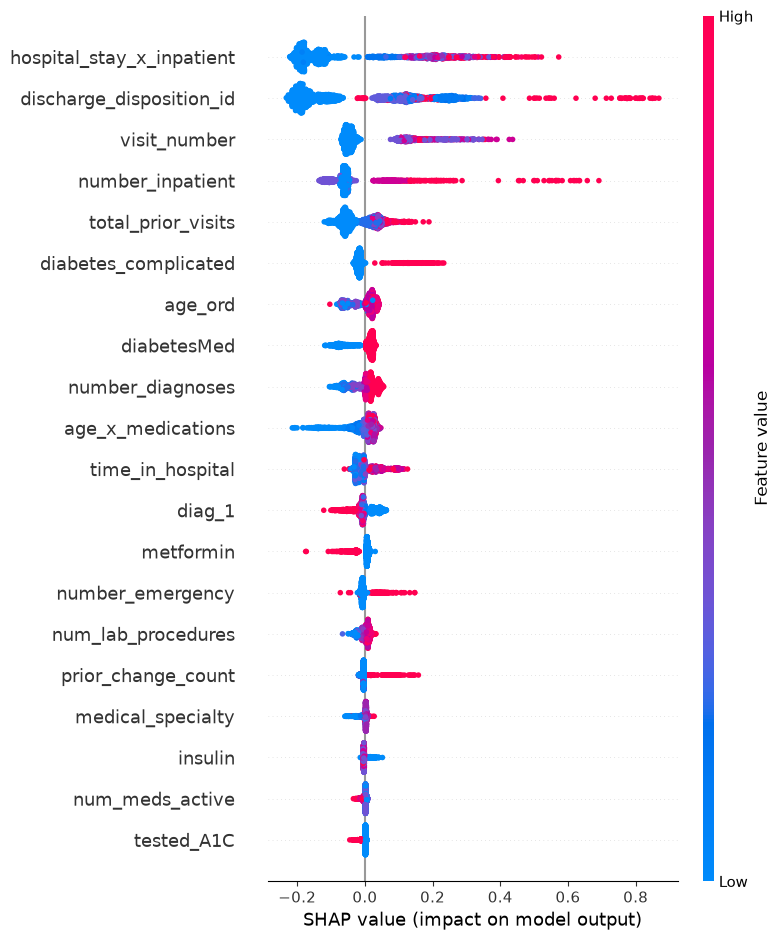

In [22]:
# ใช้ TreeExplainer กับ XGBoost ตัวที่ tuned แล้ว (เร็วกว่าอธิบาย stacking ทั้งก้อนโดยตรง)
xgb_model = xgb_pipeline.named_steps["xgboost"] if hasattr(xgb_pipeline, "named_steps") else xgb_pipeline

explainer = shap.TreeExplainer(xgb_model)
# สุ่ม sample จาก X_test มาอธิบาย (ทั้งชุดอาจช้า)
X_sample = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, show=True)

In [23]:
# ดู mean(|SHAP|) แยกเป็นตัวเลขชัดๆ ว่าฟีเจอร์ proxy ใหม่ (medication_change_count,
# num_meds_active, tested_glucose, tested_A1C, comorbidity_count) ติดอันดับหรือไม่
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_sample.columns)
print(mean_abs_shap.sort_values(ascending=False).head(20))

hospital_stay_x_inpatient    0.176424
discharge_disposition_id     0.173921
visit_number                 0.080792
number_inpatient             0.079092
total_prior_visits           0.049065
diabetes_complicated         0.029699
age_ord                      0.029228
diabetesMed                  0.029044
number_diagnoses             0.028466
age_x_medications            0.024253
time_in_hospital             0.023510
diag_1                       0.022510
metformin                    0.013521
number_emergency             0.011995
num_lab_procedures           0.011275
prior_change_count           0.008131
medical_specialty            0.005583
insulin                      0.005140
num_meds_active              0.005095
tested_A1C                   0.004569
dtype: float32


## 12. Save Final Model

In [24]:
joblib.dump(
    {
        "stacking_model": stacking_model,
        "rf_pipeline": rf_pipeline,
        "xgb_pipeline": xgb_pipeline,
        "best_threshold_f1": best_th_f1,
        "best_threshold_f2": best_th_f2,
        "best_threshold_cost": best_th_cost,
        "recommended_threshold": best_threshold,
        "label_encoders": label_encoders,
        "feature_names": X_train.columns.tolist(),
        "resampling_method_used": best_resampler_name,
    },
    "../models/final_models_v3.pkl",
)
print("Saved to ../models/final_models_v3.pkl")
print(f"Resampling method used: {best_resampler_name}")
print(f"Recommended threshold (cost-optimal): {best_threshold:.4f}")

Saved to ../models/final_models_v3.pkl
Resampling method used: class_weight_balanced (no resample)
Recommended threshold (cost-optimal): 0.6100


In [25]:
import numpy as np

np.savez(
    "../data/eval_export_05.npz",
    y_test=y_test.values if hasattr(y_test, "values") else y_test,
    y_proba=stacking_proba,
    best_threshold_f1=best_th_f1,
    best_threshold_f2=best_th_f2,
    best_threshold_cost=best_th_cost,
)
print("Exported: ../data/eval_export_05.npz")


Exported: ../data/eval_export_05.npz
